In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [195]:
df = pd.read_csv(r'C:\Users\shazi\Desktop\Customer Churn ML Project\Dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [196]:
df.head() 

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [197]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [198]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [199]:
df.groupby('Churn')['Churn'].count()

Churn
No     5174
Yes    1869
Name: Churn, dtype: int64

<Axes: xlabel='Churn', ylabel='percent'>

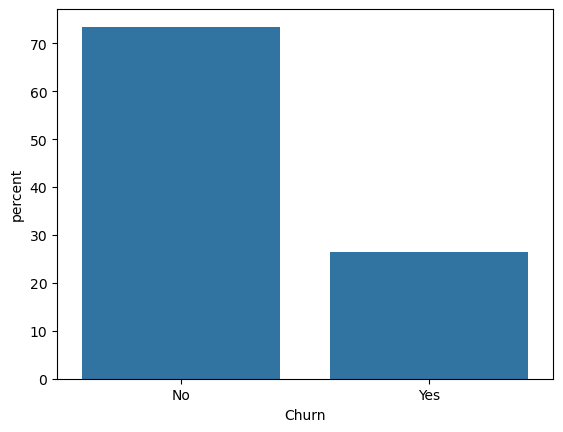

In [200]:
sns.countplot(x='Churn' , data = df , stat = 'percent' )

In [201]:
#Their is about 25% Churn Rate

<Axes: xlabel='PhoneService', ylabel='count'>

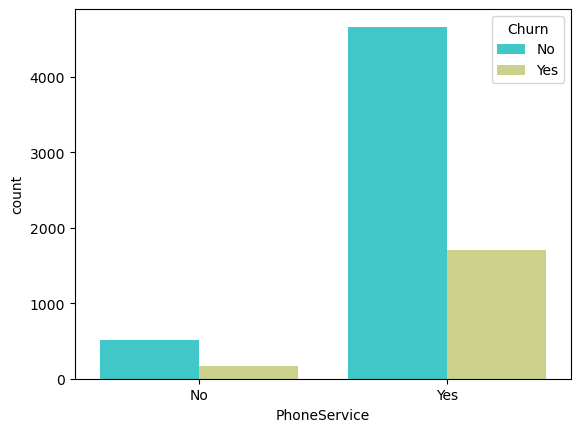

In [202]:
sns.countplot(x=df['PhoneService'] , hue = df['Churn'] ,palette='rainbow')

<Axes: xlabel='Contract', ylabel='count'>

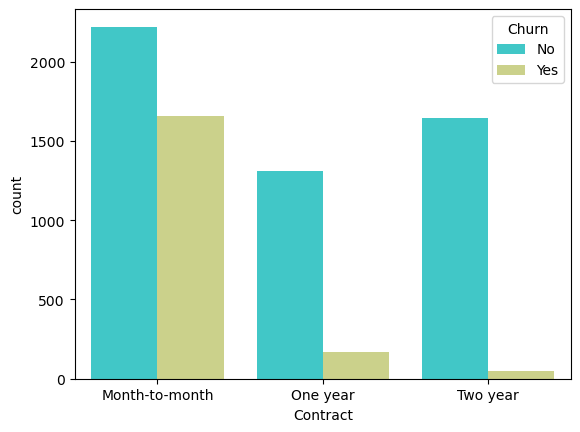

In [203]:
    sns.countplot(x=df['Contract'] , hue = df['Churn'],palette='rainbow' )

In [204]:
#People with Month to Month have a higher Churn Rate while people having One year or Two Year Contract have a very less Churn Rate Stating 
#that people give Yearly contract have a Higher Rate of Staying

<Axes: xlabel='tenure', ylabel='Density'>

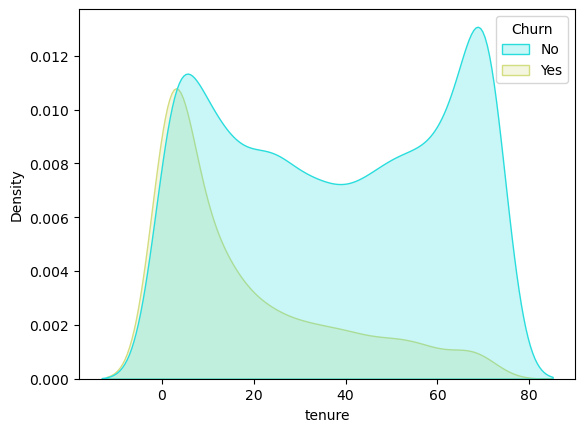

In [205]:
sns.kdeplot(x='tenure',data=df , hue = 'Churn',fill=True , palette='rainbow')

In [206]:
#Like above analysis people with more tenure have a Higher chance of sticking with the company

<Axes: xlabel='MonthlyCharges'>

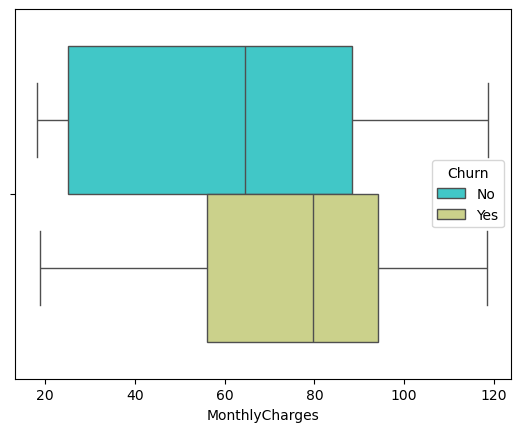

In [207]:
sns.boxplot(x = 'MonthlyCharges' , hue = 'Churn' , data = df , palette='rainbow')

In [208]:
#This visualiztion states that people with less monthly charges have a less Churn Rate as compared with people having higher
#montly charges

In [209]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [210]:
df.dropna(inplace = True)

In [211]:
df.drop(columns = 'customerID' , axis = 1 , inplace = True )

In [212]:
df.groupby('gender')['gender'].count()

gender
Female    3483
Male      3549
Name: gender, dtype: int64

In [213]:
df['is_male'] = df['gender'].map({'Male': 1 , 'Female' :0 } )
df.drop(columns = 'gender' , axis = 1,inplace = True)

In [214]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     7032 non-null   int64  
 1   Partner           7032 non-null   object 
 2   Dependents        7032 non-null   object 
 3   tenure            7032 non-null   int64  
 4   PhoneService      7032 non-null   object 
 5   MultipleLines     7032 non-null   object 
 6   InternetService   7032 non-null   object 
 7   OnlineSecurity    7032 non-null   object 
 8   OnlineBackup      7032 non-null   object 
 9   DeviceProtection  7032 non-null   object 
 10  TechSupport       7032 non-null   object 
 11  StreamingTV       7032 non-null   object 
 12  StreamingMovies   7032 non-null   object 
 13  Contract          7032 non-null   object 
 14  PaperlessBilling  7032 non-null   object 
 15  PaymentMethod     7032 non-null   object 
 16  MonthlyCharges    7032 non-null   float64
 17  

In [215]:
df.groupby('is_male')['is_male'].count()

is_male
0    3483
1    3549
Name: is_male, dtype: int64

In [216]:
df.groupby('SeniorCitizen')['SeniorCitizen'].count()

SeniorCitizen
0    5890
1    1142
Name: SeniorCitizen, dtype: int64

In [217]:
df.groupby('Partner')['Partner'].count()

Partner
No     3639
Yes    3393
Name: Partner, dtype: int64

In [218]:
df['Partner'] = df['Partner'].map({'Yes' : 1 , 'No' : 0})

In [219]:
df.groupby('Dependents')['Dependents'].count()

Dependents
No     4933
Yes    2099
Name: Dependents, dtype: int64

In [220]:
df['Dependents'] = df['Dependents'].map({'Yes' : 1 , 'No' : 0})

In [221]:
df.groupby('Dependents')['Dependents'].count()

Dependents
0    4933
1    2099
Name: Dependents, dtype: int64

In [222]:
df.groupby('PhoneService')['PhoneService'].count()

PhoneService
No      680
Yes    6352
Name: PhoneService, dtype: int64

In [223]:
df['PhoneService'] = df['PhoneService'].map({'Yes' : 1 , 'No' : 0})

In [224]:
df.groupby('PhoneService')['PhoneService'].count()

PhoneService
0     680
1    6352
Name: PhoneService, dtype: int64

In [225]:
df.groupby('MultipleLines')['MultipleLines'].count()

MultipleLines
No                  3385
No phone service     680
Yes                 2967
Name: MultipleLines, dtype: int64

In [226]:
df['MultipleLines'] = df['MultipleLines'].map({'Yes': 1, 'No': 0, 'No phone service': 0})

In [227]:
df.groupby('MultipleLines')['MultipleLines'].count()

MultipleLines
0    4065
1    2967
Name: MultipleLines, dtype: int64

In [228]:
df.groupby('InternetService')['InternetService'].count()

InternetService
DSL            2416
Fiber optic    3096
No             1520
Name: InternetService, dtype: int64

In [229]:
df = pd.get_dummies(df, drop_first=True)

In [230]:
df = df.astype(int)

In [231]:
df = df.astype({
    'MonthlyCharges': 'float',
    'TotalCharges': 'float'
})

In [232]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 30 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   SeniorCitizen                          7032 non-null   int64  
 1   Partner                                7032 non-null   int64  
 2   Dependents                             7032 non-null   int64  
 3   tenure                                 7032 non-null   int64  
 4   PhoneService                           7032 non-null   int64  
 5   MultipleLines                          7032 non-null   int64  
 6   MonthlyCharges                         7032 non-null   float64
 7   TotalCharges                           7032 non-null   float64
 8   is_male                                7032 non-null   int64  
 9   InternetService_Fiber optic            7032 non-null   int64  
 10  InternetService_No                     7032 non-null   int64  
 11  OnlineSec

In [233]:
from sklearn.preprocessing import StandardScaler

In [234]:
X = df.drop(columns=['Churn_Yes'])
y = df['Churn_Yes']
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

In [235]:
from sklearn.model_selection import train_test_split

In [236]:
X = df.drop(columns = 'Churn_Yes')
y = df['Churn_Yes']

In [237]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [238]:
from sklearn.linear_model import LogisticRegression

In [239]:
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

In [240]:
lr = LogisticRegression(class_weight='balanced')

In [241]:
lr.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [242]:
lr_pred = lr.predict(X_test)

In [243]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay

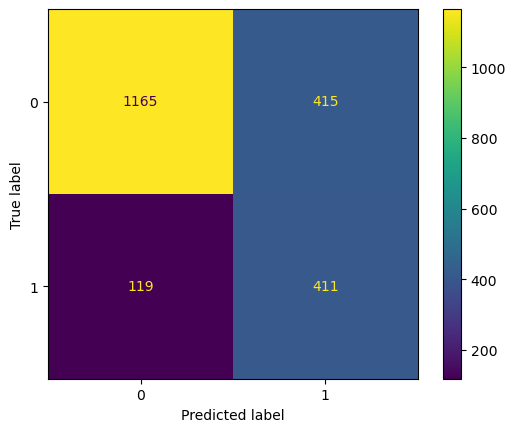

In [244]:
ConfusionMatrixDisplay.from_predictions(y_test,lr_pred)

In [245]:
print(classification_report(y_test,lr_pred))

              precision    recall  f1-score   support

           0       0.91      0.74      0.81      1580
           1       0.50      0.78      0.61       530

    accuracy                           0.75      2110
   macro avg       0.70      0.76      0.71      2110
weighted avg       0.80      0.75      0.76      2110



In [246]:
from sklearn.tree import DecisionTreeClassifier

In [247]:
dt = DecisionTreeClassifier(class_weight='balanced')

In [248]:
dt.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [249]:
dt_pred = dt.predict(X_test)

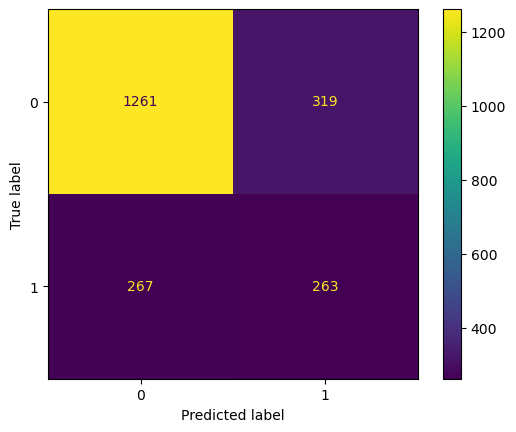

In [250]:
ConfusionMatrixDisplay.from_predictions(y_test,dt_pred)

In [251]:
print(classification_report(y_test,dt_pred))

              precision    recall  f1-score   support

           0       0.83      0.80      0.81      1580
           1       0.45      0.50      0.47       530

    accuracy                           0.72      2110
   macro avg       0.64      0.65      0.64      2110
weighted avg       0.73      0.72      0.73      2110



In [252]:
from sklearn.neighbors import KNeighborsClassifier

In [253]:
knn = KNeighborsClassifier(n_neighbors=3)

In [254]:
knn.fit(X_train,y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [255]:
knn_pred = knn.predict(X_test)

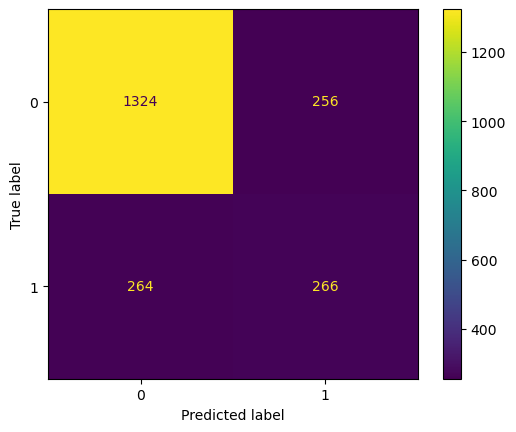

In [256]:
ConfusionMatrixDisplay.from_predictions(y_test,knn_pred)

In [257]:
print(classification_report(y_test,knn_pred))

              precision    recall  f1-score   support

           0       0.83      0.84      0.84      1580
           1       0.51      0.50      0.51       530

    accuracy                           0.75      2110
   macro avg       0.67      0.67      0.67      2110
weighted avg       0.75      0.75      0.75      2110



In [258]:
from sklearn.svm import SVC

In [259]:
svm = SVC(class_weight='balanced')

In [260]:
svm.fit(X_train,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,'balanced'
,verbose,False


In [261]:
svm_pred = svm.predict(X_test)

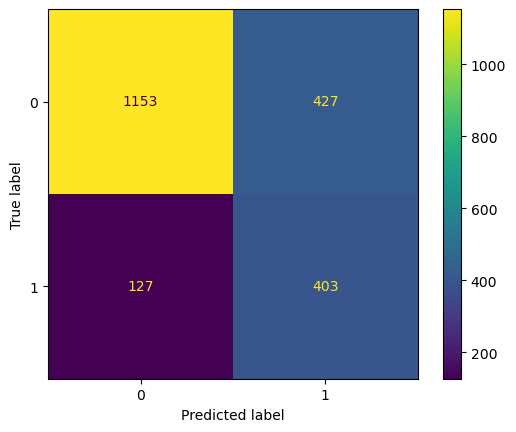

In [262]:
ConfusionMatrixDisplay.from_predictions(y_test,svm_pred)

In [263]:
print(classification_report(y_test,svm_pred))

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1580
           1       0.49      0.76      0.59       530

    accuracy                           0.74      2110
   macro avg       0.69      0.75      0.70      2110
weighted avg       0.80      0.74      0.75      2110



In [264]:
from sklearn.ensemble import RandomForestClassifier

In [265]:
rf = RandomForestClassifier(n_estimators=100, random_state=42,class_weight='balanced')

In [266]:
rf.fit(X_train,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [267]:
rf_pred = rf.predict(X_test)

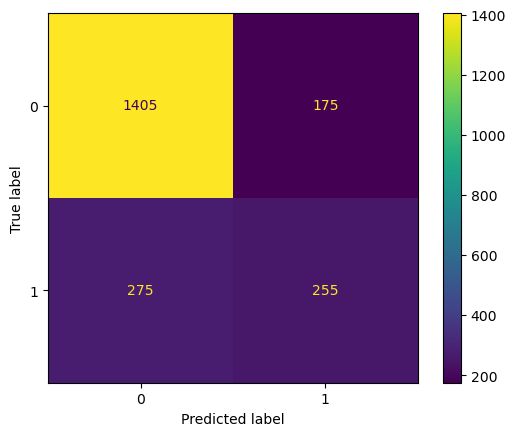

In [268]:
ConfusionMatrixDisplay.from_predictions(y_test,rf_pred)

In [269]:
print(classification_report(y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1580
           1       0.59      0.48      0.53       530

    accuracy                           0.79      2110
   macro avg       0.71      0.69      0.70      2110
weighted avg       0.78      0.79      0.78      2110



In [270]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

lr_acc = accuracy_score(y_test, lr_pred)
lr_prec = precision_score(y_test, lr_pred)
lr_rec = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
lr_roc = roc_auc_score(y_test, lr_pred)

In [271]:

data = {
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM'],
    'Accuracy': [0.80, 0.71, 0.79, 0.73, 0.78],  # Replace with your actual computed variables
    'Precision': [0.63, 0.44, 0.59, 0.46, 0.62],
    'Recall': [0.54, 0.52, 0.48, 0.51, 0.51],
    'F1-Score': [0.58, 0.48, 0.53, 0.48, 0.56],
    'ROC-AUC': [0.84, 0.64, 0.82, 0.70, 0.81]
}

comparison_df = pd.DataFrame(data)

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.80,0.63,0.54,0.58,0.84
1,Decision Tree,0.71,0.44,0.52,0.48,0.64
2,Random Forest,0.79,0.59,0.48,0.53,0.82
3,KNN,0.73,0.46,0.51,0.48,0.70
4,SVM,0.78,0.62,0.51,0.56,0.81


In [272]:
import joblib

joblib.dump(lr, "churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [273]:
import joblib

# 1. Save the exact list of feature columns expected by the model
joblib.dump(list(X_train.columns), 'model_columns.pkl')

# 2. Save the fitted scaler (if you scaled features before predicting in Streamlit)
joblib.dump(scaler, 'scaler.pkl')

# 3. Save the trained model
joblib.dump(lr, 'model.pkl')

print("Saved model, scaler, and feature columns successfully!")

Saved model, scaler, and feature columns successfully!
